In [19]:
# reload src/config.py automatically whenever it changes
%load_ext autoreload
%autoreload 2

# import project settings
import sys
sys.path.append("..")
from src import config

# import required packages
import pandas as pd
import shutil
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
# import labels -  skip rows that can't be parsed
styles = pd.read_csv(config.STYLES_CSV, on_bad_lines="skip")

# how many rows did we lose?
with open(config.STYLES_CSV, encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1  

print(f"Rows in file: {total_rows}, loaded: {len(styles)}, skipped: {total_rows - len(styles)}")
styles.head()

Rows in file: 44446, loaded: 44424, skipped: 22


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [21]:
# check every label has an image. (each id from styles.csv should be in our images folder(example: 15970.jpg))
# get the ids of every image in the folder
image_ids = {path.stem for path in config.RAW_IMAGES_DIR.glob("*.jpg")}

print(f"Images in folder: {len(image_ids)}")

# check which products have an image
styles["image_exists"] = styles["id"].astype(str).isin(image_ids)
print(styles["image_exists"].value_counts())

Images in folder: 44441
image_exists
True     44419
False        5
Name: count, dtype: int64


In [22]:
# keep only products that have an image
styles = styles.loc[styles["image_exists"]].copy()

In [23]:
# build the full image path for each product
styles["filepath"] = [config.RAW_IMAGES_DIR / f"{product_id}.jpg" for product_id in styles["id"]]

print(f"Products with an image: {len(styles)}")

# preview - show the image path relative to the project
preview = styles.head().copy()
preview["filepath"] = [path.relative_to(config.PROJECT_ROOT) for path in preview["filepath"]]
preview

Products with an image: 44419


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image_exists,filepath
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt,True,data/raw/images/15970.jpg
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans,True,data/raw/images/39386.jpg
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch,True,data/raw/images/59263.jpg
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants,True,data/raw/images/21379.jpg
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt,True,data/raw/images/53759.jpg


In [24]:
# keep only the classes we're classifying
product_data = styles.loc[styles["articleType"].isin(config.CLASSES), ["id", "articleType", "filepath"]].copy()

In [26]:
# check every class name was found

product_data["articleType"].value_counts()

articleType
Tshirts         7066
Shirts          3215
Casual Shoes    2845
Watches         2542
Sports Shoes    2036
Handbags        1759
Name: count, dtype: int64

In [27]:
percentage_series = product_data["articleType"].value_counts(normalize=True) * 100
print(percentage_series)

articleType
Tshirts         36.304783
Shirts          16.518522
Casual Shoes    14.617479
Watches         13.060679
Sports Shoes    10.460874
Handbags         9.037661
Name: proportion, dtype: float64


In [28]:
# Create a function for creating plot
def plot_category_distribution(data, variable):
    counts = data[variable].value_counts(ascending=True)

    fig, axes = plt.subplots(1, 2, figsize=(6, 4))

    sns.countplot(
        x=variable,
        data=data,
        order=counts.index,
        ax=axes[0]
    )
    axes[0].set_title(f"Count Plot - {variable}")
    axes[0].tick_params(axis="x", labelrotation=90)

    axes[1].pie(counts, labels=counts.index, autopct="%0.2f%%")
    axes[1].set_title(f"Pie Chart - {variable}")

    plt.tight_layout()
    plt.show()

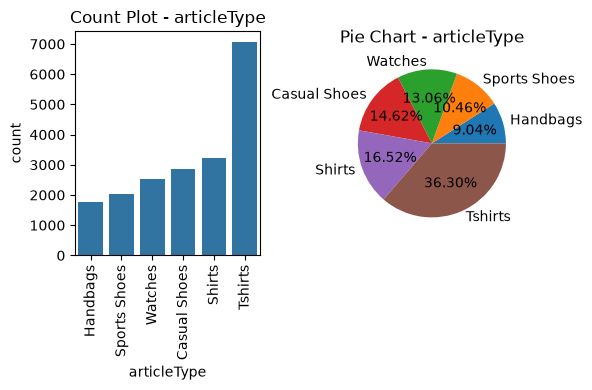

In [29]:
plot_category_distribution(product_data,"articleType")

In [30]:
# take the same number of images from each class (capped by the smallest class)
smallest_class = product_data["articleType"].value_counts().min()
images_per_class = min(config.IMAGES_PER_CLASS, smallest_class)

sampled_data = product_data.groupby("articleType").sample(n=images_per_class, random_state=config.RANDOM_SEED)

print(f"Smallest class: {smallest_class} images")
print(f"Images per class: {images_per_class}")
print(sampled_data["articleType"].value_counts())


Smallest class: 1759 images
Images per class: 1000
articleType
Casual Shoes    1000
Handbags        1000
Shirts          1000
Sports Shoes    1000
Tshirts         1000
Watches         1000
Name: count, dtype: int64


In [31]:
# check for images size
print(sampled_data["filepath"].apply(lambda path: Image.open(path).size).value_counts())

filepath
(60, 80)    5997
(53, 80)       2
(60, 75)       1
Name: count, dtype: int64


In [32]:
# first split: 60% training, 40% held back for validation & test

train_data, test_validate_data = train_test_split(sampled_data, train_size=config.TRAIN_SPLIT, 
                                                  stratify=sampled_data["articleType"],
                                                  random_state=config.RANDOM_SEED)

# second split: divide the 40% into validation (30%) and test (10%) 
validation_share = config.VALIDATION_SPLIT / (config.VALIDATION_SPLIT + config.TEST_SPLIT)

validation_size = round(validation_share * len(test_validate_data))

validation_data, test_data = train_test_split(test_validate_data,
                                              train_size=validation_size,
                                              stratify=test_validate_data["articleType"],
                                              random_state=config.RANDOM_SEED)

print(f"Training: {len(train_data)}, Validation: {len(validation_data)}, Test: {len(test_data)}")

Training: 3600, Validation: 1800, Test: 600


In [33]:
# which data goes into which folder
splits = {config.TRAINING_DIR: train_data,
          config.VALIDATION_DIR: validation_data,
          config.TEST_DIR: test_data}

for split_dir, split_data in splits.items():

    # always start fresh
    if split_dir.exists():
        shutil.rmtree(split_dir)

    for _, row in split_data.iterrows():
        class_dir = split_dir / row["articleType"]
        class_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy(row["filepath"], class_dir / row["filepath"].name)

# check the result
for split_dir in splits:
    counts = {}
    for class_dir in sorted(split_dir.iterdir()):
        images = list(class_dir.glob("*.jpg"))
        counts[class_dir.name] = len(images)
    print(split_dir.name, counts)

training {'Casual Shoes': 600, 'Handbags': 600, 'Shirts': 600, 'Sports Shoes': 600, 'Tshirts': 600, 'Watches': 600}
validation {'Casual Shoes': 300, 'Handbags': 300, 'Shirts': 300, 'Sports Shoes': 300, 'Tshirts': 300, 'Watches': 300}
test {'Casual Shoes': 100, 'Handbags': 100, 'Shirts': 100, 'Sports Shoes': 100, 'Tshirts': 100, 'Watches': 100}


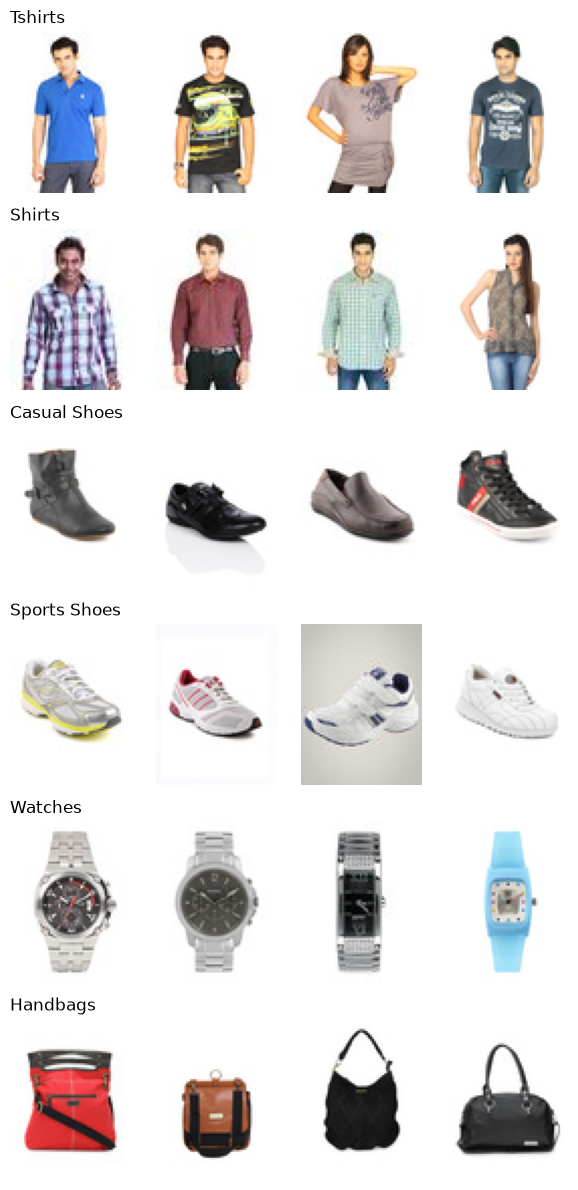

In [34]:
# show 4 example images per class & save for write-up
fig, axes = plt.subplots(len(config.CLASSES), 4, figsize=(6, 12))

for row_idx, class_name in enumerate(config.CLASSES):
    examples = train_data.loc[train_data["articleType"] == class_name].head(4)
    for col_idx, filepath in enumerate(examples["filepath"]):
        axes[row_idx, col_idx].imshow(Image.open(filepath))
        axes[row_idx, col_idx].axis("off")
    axes[row_idx, 0].set_title(class_name, loc="left")

plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "product-image-examples.png", dpi=150)
plt.show()

In [47]:
modes = sampled_data.groupby(sampled_data['mode']).size()
modes

mode
L        61
RGB    5939
dtype: int64

In [ ]:
# check the color mode of every image: "RGB" = color, "L" = greyscale
sampled_data["mode"] = [Image.open(path).mode for path in sampled_data["filepath"]]

# count images by class and color mode
modes_by_class = sampled_data.groupby(["articleType", "mode"]).size().unstack(fill_value=0)
modes_by_class

mode,L,RGB
articleType,,
Casual Shoes,14,986
Handbags,10,990
Shirts,0,1000
Sports Shoes,8,992
Tshirts,0,1000
Watches,29,971


In [52]:
sampled_data.head()

,id,articleType,filepath,mode
6641,15259,Casual Shoes,/Users/lemuel/Documents/de/project/data-engine...,RGB
34540,25420,Casual Shoes,/Users/lemuel/Documents/de/project/data-engine...,RGB
17836,54739,Casual Shoes,/Users/lemuel/Documents/de/project/data-engine...,RGB
17300,6497,Casual Shoes,/Users/lemuel/Documents/de/project/data-engine...,RGB
19207,15502,Casual Shoes,/Users/lemuel/Documents/de/project/data-engine...,RGB


## Summary

**Data loading**

| Step | Result |
|---|---|
| Rows in `styles.csv` | 44,446 |
| Rows skipped (could not be parsed) | 22 (0.05%) |
| Products without an image | 5 |
| Products used | 44,419 |

**Classes & balancing**

* Filtered to 6 classes from `articleType`: Tshirts, Shirts, Casual Shoes, Sports Shoes, Watches, Handbags
* Classes were imbalanced, so we took a random, balanced sample of **1,000 images per class** (6,000 total)

**Image size**

* 5,997 of 6,000 images are **60 x 80 pixels** (portrait)
* We keep this original size & shape (`IMG_HEIGHT = 80`, `IMG_WIDTH = 60`) to avoid distorting products

**Image Color**

* 61 of 6,000 images (1%) are grayscale - all product-only photos of Watches (29), Casual Shoes (14), Handbags (10) & Sports Shoes (8). No Shirts or Tshirts are grayscale
* All images are loaded as 3-channel RGB, so every image has the same shape
* With so few grayscale images per class, this is unlikely to create a shortcut for the network

**Training / Validation / Test split** (stratified by class)

| Split | Share | Images | Per class |
|---|---|---|---|
| Training | 60% | 3,600 | 600 |
| Validation | 30% | 1,800 | 300 |
| Test | 10% | 600 | 100 |

**Outputs**

* `data/processed/` - training, validation & test folders, one sub-folder per class
* `data/processed/splits.csv` - record of which product went into which split
* `reports/figures/product-image-examples.png` - example images per class

**Next:** `02_baseline_network.ipynb` - build & train our first CNN